In [ ]:

import torch
import os
import shutil

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No GPU detected. Do not download the dataset yet.")

print("\nColab storage:")
print(shutil.disk_usage("/content"))

print("\nFiles currently in /content:")
print(os.listdir("/content"))


GPU available: True
GPU name: Tesla T4
GPU memory: 14.56 GB

Colab storage:
usage(total=120942624768, used=86757376, free=120839090176)

Files currently in /content:
['.config', 'sample_data']


In [ ]:

import os

old_files = [
    "best_msl.pt",
    "baseline_results.csv",
    "train_log.csv"
]

print("Checking previous experiment files:\n")

for file in old_files:
    path = os.path.join("/content", file)

    if os.path.exists(path):
        size = os.path.getsize(path) / (1024**2)
        print(f"FOUND: {file} | {size:.2f} MB")
    else:
        print(f"MISSING: {file}")


Checking previous experiment files:

FOUND: best_msl.pt | 14.25 MB
FOUND: baseline_results.csv | 0.00 MB
FOUND: train_log.csv | 0.00 MB


In [ ]:

# RECOVERY CELL 1 — fresh project setup (CPU is sufficient)

import os
import sys
import zipfile

from google.colab import files

PROJ = "/content/mars_compression"

folders = [
    "splits",
    "checkpoints/FROZEN_baseline",
    "results",
    "figures",
    "logs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJ, folder), exist_ok=True)

def save_to_laptop(paths, zip_name):
    output = f"/content/{zip_name}.zip"

    with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as zf:
        for path in paths:
            if not os.path.exists(path):
                print("Skipping missing path:", path)
                continue

            if os.path.isdir(path):
                for root, _, filenames in os.walk(path):
                    for filename in filenames:
                        full = os.path.join(root, filename)
                        zf.write(full, os.path.relpath(full, PROJ))
            else:
                zf.write(
                    path,
                    os.path.relpath(path, PROJ)
                    if path.startswith(PROJ)
                    else os.path.basename(path)
                )

    print("Created:", output)
    print("Size:", round(os.path.getsize(output) / 2**20, 2), "MB")
    files.download(output)

print("Project folder:", PROJ)
print("Python:", sys.version.split()[0])
print("Project setup completed!")


Project folder: /content/mars_compression
Python: 3.13.18
Project setup completed!


In [ ]:

# RECOVERY CELL 2 — upload and verify frozen split v3

from google.colab import files
import zipfile
import json
import hashlib
import pandas as pd
import os

uploaded = files.upload()

zip_name = "save02_split_v3_frozen.zip"

assert zip_name in uploaded, "Please upload save02_split_v3_frozen.zip"

with zipfile.ZipFile(zip_name) as zf:
    zf.extractall(PROJ)

manifest_path = f"{PROJ}/splits/split_v3_FROZEN.json"

with open(manifest_path) as f:
    manifest = json.load(f)

for name, details in manifest["files"].items():
    path = f"{PROJ}/splits/split_v3_{name}.csv"

    with open(path, "rb") as f:
        actual_md5 = hashlib.md5(f.read()).hexdigest()

    assert actual_md5 == details["md5"], f"Checksum mismatch: {name}"
    assert len(pd.read_csv(path)) == details["rows"], f"Row count mismatch: {name}"

print("FROZEN SPLITS RESTORED AND VERIFIED")
print({k: v["rows"] for k, v in manifest["files"].items()})


Saving save02_split_v3_frozen.zip to save02_split_v3_frozen.zip
FROZEN SPLITS RESTORED AND VERIFIED
{'train': 9803, 'val': 1192, 'test_msl': 311, 'test_mer': 195}


In [ ]:
import requests

record_url = "https://zenodo.org/api/records/15995036"

response = requests.get(record_url, timeout=30)
response.raise_for_status()

record = response.json()

target_name = "ai4mars-dataset-merged-0.6.zip"

dataset_file = next(
    (f for f in record["files"] if f["key"] == target_name),
    None
)

if dataset_file is None:
    raise FileNotFoundError(f"{target_name} not found in Zenodo record.")

dataset_url = dataset_file["links"]["self"]
dataset_size = dataset_file["size"]
dataset_checksum = dataset_file.get("checksum")

print("Dataset:", dataset_file["key"])
print("Size:", round(dataset_size / (1024**3), 2), "GiB")
print("Checksum:", dataset_checksum)
print("Download URL retrieved:", bool(dataset_url))

Dataset: ai4mars-dataset-merged-0.6.zip
Size: 15.12 GiB
Checksum: md5:daf80a86021253292e6c425f97baa5c6
Download URL retrieved: True


In [ ]:
import os
import subprocess

ZIP = "/content/ai4mars-dataset-merged-0.6.zip"

if os.path.exists(ZIP):
    current_size = os.path.getsize(ZIP)
    print("Existing file found:", round(current_size / (1024**3), 2), "GiB")
    print("We will attempt to resume the download.")
else:
    print("Starting a fresh download.")

result = subprocess.run(
    ["wget", "-c", "--show-progress", "-O", ZIP, dataset_url]
)

if result.returncode != 0:
    print("Download did not finish successfully. Do not delete the partial file.")
    print("We can attempt to resume it.")
else:
    actual_size = os.path.getsize(ZIP)
    print("\nDownload command completed.")
    print("Downloaded size:", round(actual_size / (1024**3), 2), "GiB")
    print("Expected size:", round(dataset_size / (1024**3), 2), "GiB")

Starting a fresh download.

Download command completed.
Downloaded size: 15.12 GiB
Expected size: 15.12 GiB


In [ ]:
import hashlib

expected_md5 = dataset_checksum.split(":")[-1]

h = hashlib.md5()
with open(ZIP, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        h.update(chunk)

actual_md5 = h.hexdigest()
print("Expected:", expected_md5)
print("Actual:  ", actual_md5)
print("MATCH" if actual_md5 == expected_md5 else "MISMATCH - do not continue")

Expected: daf80a86021253292e6c425f97baa5c6
Actual:   daf80a86021253292e6c425f97baa5c6
MATCH


In [ ]:
import zipfile
import os

ZIP = "/content/ai4mars-dataset-merged-0.6.zip"

z = zipfile.ZipFile(ZIP, "r")

all_files = z.namelist()

print("Total entries in archive:", len(all_files))

print("\nTop-level folders:")
top_folders = sorted({
    path.split("/")[1]
    for path in all_files
    if path.startswith("ai4mars-dataset-merged-0.6/")
    and len(path.split("/")) > 2
})

for folder in top_folders:
    print("-", folder)

print("\nSample dataset paths:")
for path in all_files[:30]:
    print(path)

print("\nArchive opened successfully!")

Total entries in archive: 146179

Top-level folders:
- m2020
- mer
- msl

Sample dataset paths:
ai4mars-dataset-merged-0.6/
ai4mars-dataset-merged-0.6/changelog.md
ai4mars-dataset-merged-0.6/info.md
ai4mars-dataset-merged-0.6/label_keys.json
ai4mars-dataset-merged-0.6/m2020/
ai4mars-dataset-merged-0.6/m2020/images/
ai4mars-dataset-merged-0.6/m2020/images/DATA_NOTES.txt
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/VgncRawLeft_0684693433-41490_rectified.jpeg
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/VgncRawLeft_0684693508-32241_rectified.jpeg
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/VgncRawLeft_0684693533-49468_rectified.jpeg
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/VgncRawLeft_0684693577-45625_rectified.jpeg
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/VgncRawLeft_0684693600-27358_rectified.jpeg
ai4mars-dataset-merged-0.6/m2020/images/HAFIQ/VgncRawLeft_0684693623-01766_rectified.jpeg
ai4mars-dataset-merged-0.6/m2020/images/H

In [ ]:
import zipfile
import re
import io
import os
import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm

ROOT = "ai4mars-dataset-merged-0.6/"

# Reuse the archive already opened
infos = {
    i.filename[len(ROOT):]: i
    for i in z.infolist()
    if i.filename.startswith(ROOT)
    and not i.filename.endswith("/")
}

def stem(path):
    return os.path.splitext(os.path.basename(path))[0]

def is_jpg(path):
    return path.lower().endswith((".jpg", ".jpeg"))

# --------------------------------------------------
# 1. Index Curiosity Navcam images
# --------------------------------------------------

msl_img = {}
collisions = 0

for p in infos:
    if p.startswith("msl/ncam/images/") and is_jpg(p):
        key = "_".join(stem(p).split("_")[:2])

        if key in msl_img:
            collisions += 1

        msl_img[key] = p

# --------------------------------------------------
# 2. Index MER images
# --------------------------------------------------

mer_test_img = {
    stem(p): p
    for p in infos
    if p.startswith("mer/images/test/") and is_jpg(p)
}

mer_eff_img = {
    stem(p): p
    for p in infos
    if p.startswith("mer/images/eff/") and is_jpg(p)
}

print("MSL Navcam images:", len(msl_img))
print("MSL key collisions:", collisions)
print("MER test images:", len(mer_test_img))
print("MER eff images:", len(mer_eff_img))

# Check whether MER test images also appear in eff
both = set(mer_test_img) & set(mer_eff_img)

same = sum(
    infos[mer_test_img[s]].CRC == infos[mer_eff_img[s]].CRC
    for s in both
)

print("MER test stems also in eff:", len(both))
print("Byte-identical MER images:", same)

# --------------------------------------------------
# 3. Define annotation groups
# --------------------------------------------------

LABELS = {
    "msl_crowd_train": (
        "msl",
        "msl/ncam/labels/train/"
    ),
    "msl_gold_min1": (
        "msl",
        "msl/ncam/labels/test/masked-gold-min1-100agree/"
    ),
    "msl_gold_min2": (
        "msl",
        "msl/ncam/labels/test/masked-gold-min2-100agree/"
    ),
    "msl_gold_min3": (
        "msl",
        "msl/ncam/labels/test/masked-gold-min3-100agree/"
    ),
    "mer_gold_min1": (
        "mer",
        "mer/labels/test/masked-gold-min1-100agree/"
    ),
    "mer_gold_min2": (
        "mer",
        "mer/labels/test/masked-gold-min2-100agree/"
    ),
    "mer_gold_min3": (
        "mer",
        "mer/labels/test/masked-gold-min3-100agree/"
    ),
}

# --------------------------------------------------
# 4. Match labels with their images
# --------------------------------------------------

rows = []

for name, (rover, prefix) in LABELS.items():

    label_paths = [
        p for p in infos
        if p.startswith(prefix)
        and p.lower().endswith(".png")
    ]

    for p in label_paths:

        base = re.sub(
            r'(?:_\d+)?(?:_T\d+)?_merged\d*$',
            '',
            stem(p)
        )

        if rover == "msl":
            image = msl_img.get(
                "_".join(base.split("_")[:2])
            )
        else:
            image = mer_test_img.get(base)

        rows.append({
            "set": name,
            "rover": rover,
            "label_path": p,
            "image_path": image
        })

df = pd.DataFrame(rows)

print("\nLabel-to-image matching:")
print(
    df.groupby("set").agg(
        labels=("label_path", "count"),
        matched=("image_path", lambda s: s.notna().sum())
    )
)

# --------------------------------------------------
# 5. Inspect masks and class distributions
# --------------------------------------------------

def mask_stats(path):

    mask = np.array(
        Image.open(
            io.BytesIO(z.read(ROOT + path))
        )
    )

    counts = np.bincount(
        mask.ravel(),
        minlength=256
    )

    total = mask.size

    return {
        "height": mask.shape[0],
        "width": mask.shape[1],
        "labeled_frac": 1 - counts[255] / total,
        "bad_px": int(
            total - counts[:4].sum() - counts[255]
        ),
        **{
            f"class_{k}": counts[k] / total
            for k in range(4)
        }
    }

stats = [
    mask_stats(p)
    for p in tqdm(df.label_path)
]

df = pd.concat(
    [df, pd.DataFrame(stats)],
    axis=1
)

# --------------------------------------------------
# 6. Summarise annotation coverage
# --------------------------------------------------

summary = df.groupby("set").agg(
    n=("label_path", "count"),
    matched=("image_path", lambda s: s.notna().sum()),
    mean_labeled=("labeled_frac", "mean"),
    at_least_10pct=("labeled_frac", lambda x: (x >= 0.10).sum()),
    at_least_30pct=("labeled_frac", lambda x: (x >= 0.30).sum()),
    bad_pixels=("bad_px", "sum"),
    image_sizes=("height", lambda x: sorted(set(x)))
).round(3)

print("\nANNOTATION SUMMARY")
display(summary)

# --------------------------------------------------
# 7. Save the full index
# --------------------------------------------------

os.makedirs(f"{PROJ}/splits", exist_ok=True)

index_path = f"{PROJ}/splits/index_v2_with_stats.csv"

df.to_csv(index_path, index=False)

print("\nFull index saved to:", index_path)
print("Total annotation records:", len(df))

MSL Navcam images: 18127
MSL key collisions: 0
MER test images: 204
MER eff images: 16300
MER test stems also in eff: 204
Byte-identical MER images: 204

Label-to-image matching:
                 labels  matched
set                             
mer_gold_min1       204      204
mer_gold_min2       204      204
mer_gold_min3       204      204
msl_crowd_train   16064    16064
msl_gold_min1       322      322
msl_gold_min2       322      322
msl_gold_min3       322      322


  0%|          | 0/17642 [00:00<?, ?it/s]


ANNOTATION SUMMARY


,n,matched,mean_labeled,at_least_10pct,at_least_30pct,bad_pixels,image_sizes
set,,,,,,,
mer_gold_min1,204,204,0.602,195,183,0,[1024]
mer_gold_min2,204,204,0.478,188,160,0,[1024]
mer_gold_min3,204,204,0.260,121,87,0,[1024]
msl_crowd_train,16064,16064,0.556,15323,13429,0,[1024]
msl_gold_min1,322,322,0.575,311,282,0,[1024]
msl_gold_min2,322,322,0.484,299,247,0,[1024]
msl_gold_min3,322,322,0.346,256,173,0,[1024]



Full index saved to: /content/mars_compression/splits/index_v2_with_stats.csv
Total annotation records: 17642


In [ ]:
# CELL 10 — Backup dataset index

save_to_laptop(
    [f"{PROJ}/splits/index_v2_with_stats.csv"],
    "backup_01_dataset_index"
)

Created: /content/backup_01_dataset_index.zip
Size: 0.56 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CELL 11 — Extract Mars sol information

import re
import os
import numpy as np
import pandas as pd

index_path = f"{PROJ}/splits/index_v2_with_stats.csv"

df = pd.read_csv(index_path)

def extract_sol(image_path):
    if not isinstance(image_path, str):
        return np.nan

    filename = os.path.basename(image_path)

    # Curiosity image filename
    match = re.search(r'_(\d{9})EDR_F(\d{4})', filename)

    if match:
        return int(match.group(2))

    return np.nan

df["sol"] = df["image_path"].apply(extract_sol)

print("Total records:", len(df))
print("Records with sol information:", df["sol"].notna().sum())

print("\nCuriosity crowdsourced sol statistics:")

crowd = df[df["set"] == "msl_crowd_train"]

print("Unique sols:", crowd["sol"].nunique())
print("Minimum sol:", crowd["sol"].min())
print("Maximum sol:", crowd["sol"].max())

print("\nImages per sol (first 15):")
display(
    crowd.groupby("sol").size().reset_index(name="images").head(15)
)

print("\nMissing sol values:")
print(crowd["sol"].isna().sum())

Total records: 17642
Records with sol information: 17030

Curiosity crowdsourced sol statistics:
Unique sols: 187
Minimum sol: 10.0
Maximum sol: 771.0

Images per sol (first 15):


,sol,images
0,10.0,1
1,20.0,31
2,30.0,100
3,40.0,74
4,41.0,16
5,42.0,76
6,43.0,62
7,50.0,231
8,51.0,186
9,52.0,35



Missing sol values:
0


In [ ]:
# CELL 12 — Check sol and SCLK relationship

import pandas as pd
import numpy as np
import os
import re

idx = pd.read_csv(
    f"{PROJ}/splits/index_v2_with_stats.csv"
)

crowd = idx[idx["set"] == "msl_crowd_train"].copy()

def get_sclk(path):
    name = os.path.basename(path)
    match = re.search(r'_(\d{9})EDR', name)
    return int(match.group(1)) if match else np.nan

crowd["sclk"] = crowd["image_path"].apply(get_sclk)
crowd["sol_filename"] = crowd["image_path"].apply(extract_sol)

print("Missing SCLK:", crowd["sclk"].isna().sum())
print("Missing filename sol:", crowd["sol_filename"].isna().sum())

print("\nSCLK range:", crowd["sclk"].min(), "-", crowd["sclk"].max())
print("Filename sol range:", crowd["sol_filename"].min(), "-", crowd["sol_filename"].max())

print("\nSample comparison:")
display(crowd[["image_path", "sclk", "sol_filename"]].head(10))

Missing SCLK: 0
Missing filename sol: 0

SCLK range: 397586934 - 626441991
Filename sol range: 10 - 771

Sample comparison:


,image_path,sclk,sol_filename
0,msl/ncam/images/edr/NLA_397586934EDR_F0010008A...,397586934,10
1,msl/ncam/images/edr/NLA_397681339EDR_F0020000A...,397681339,20
2,msl/ncam/images/edr/NLA_397681372EDR_F0020000A...,397681372,20
3,msl/ncam/images/edr/NLA_397681398EDR_F0020000A...,397681398,20
4,msl/ncam/images/edr/NLA_397681429EDR_F0020000A...,397681429,20
5,msl/ncam/images/edr/NLA_397681455EDR_F0020000A...,397681455,20
6,msl/ncam/images/edr/NLA_397681486EDR_F0020000A...,397681486,20
7,msl/ncam/images/edr/NLA_397681520EDR_F0020000A...,397681520,20
8,msl/ncam/images/edr/NLA_397681553EDR_F0020000A...,397681553,20
9,msl/ncam/images/edr/NLA_397681586EDR_F0020000A...,397681586,20


In [ ]:
import numpy as np
import pandas as pd

crowd = idx[idx["set"] == "msl_crowd_train"].copy()

SOL_SECONDS = 88775

crowd["sclk"] = crowd["image_path"].apply(get_sclk)

t0 = crowd["sclk"].min()

crowd["approx_sol"] = (
    (crowd["sclk"] - t0) // SOL_SECONDS
).astype(int)

crowd["time_block"] = crowd["approx_sol"] // 10

print("Unique approximate sols:", crowd["approx_sol"].nunique())
print("Number of 10-sol blocks:", crowd["time_block"].nunique())

print("\nImages per 10-sol block:")
print(crowd["time_block"].value_counts().sort_index().to_string())

print("\nApproximate sol range:",
      crowd["approx_sol"].min(),
      "to",
      crowd["approx_sol"].max())

Unique approximate sols: 1515
Number of 10-sol blocks: 245

Images per 10-sol block:
time_block
0       34
1       42
2       86
3       44
4       89
5      137
6       26
7       17
8       15
9       17
10      21
11      46
12      70
13      39
14      38
15      54
16      94
17      35
18      10
22      42
23       1
26     168
27      57
28      11
29      53
30      76
31      45
32      64
33      75
34      93
35      70
36      77
37     142
38      64
39      68
40      91
41      54
42      71
43      91
44       7
45      41
46      20
47      69
48      36
49      32
50     107
51     145
52     162
53     113
54     155
55     154
56     112
57      64
58      84
59      88
60      93
61      39
62      51
63      86
64      65
65      75
66     146
67      95
68     163
69      46
70     146
71      86
72      49
73      66
74      83
75      69
76      13
77      45
78      87
79     136
80      61
81      53
82      25
83      52
84       7
85       6
86      55
87

In [ ]:
# SPLIT CELL v2 — filename sol, no approx sol
import re, os, json, numpy as np, pandas as pd

idx = pd.read_csv(f"{PROJ}/splits/index_v2_with_stats.csv")
print("columns:", list(idx.columns))

# labelled-fraction column (auto-detect)
LF = next((c for c in ["labeled_frac", "labeled_fraction", "labelled_frac", "frac_labeled"]
           if c in idx.columns), None)
assert LF, "No labelled-fraction column found -> paste me the column list above"
idx = idx.rename(columns={LF: "labeled_frac"})

# class columns (auto-detect)
CC = [f"class_{k}" for k in range(4)]
assert all(c in idx.columns for c in CC), "class_0..class_3 not found -> paste me the column list above"

# sol from filename: ..._F0010008A... -> 10
def sol_from_name(p):
    m = re.search(r'_F(\d{4})', os.path.basename(p)) if isinstance(p, str) else None
    return int(m.group(1)) if m else np.nan
idx["sol"] = idx["image_path"].map(sol_from_name)

TRAIN_MIN, TEST_MIN, BLOCK, VAL_FRAC, SEED = 0.30, 0.10, 10, 0.10, 0

pool = idx[(idx["set"] == "msl_crowd_train") & (idx["labeled_frac"] >= TRAIN_MIN)].copy()
assert pool["sol"].notna().all(), "some training images have no sol"
pool["sol"] = pool["sol"].astype(int)
pool["block"] = pool["sol"] // BLOCK
print("train pool:", len(pool), "| unique sols:", pool["sol"].nunique(),
      "| sol range:", pool["sol"].min(), "-", pool["sol"].max())

# validation = whole 10-sol blocks, about 10% of the pool
rng = np.random.RandomState(SEED)
blocks = pool["block"].unique(); rng.shuffle(blocks)
val_blocks, n = [], 0
for b in blocks:
    if n >= VAL_FRAC * len(pool): break
    val_blocks.append(int(b)); n += int((pool["block"] == b).sum())
val = pool[pool["block"].isin(val_blocks)]

# train = everything not within +-1 sol of any validation sol
buf = {s + d for s in set(val["sol"]) for d in (-1, 0, 1)}
train = pool[~pool["sol"].isin(buf)]
print(f"\nTRAIN {len(train)} | VAL {len(val)} | buffer-dropped {len(pool)-len(train)-len(val)}")
print("val blocks:", sorted(val_blocks))

test_msl = idx[(idx["set"] == "msl_gold_min1") & (idx["labeled_frac"] >= TEST_MIN)].copy()
test_mer = idx[(idx["set"] == "mer_gold_min1") & (idx["labeled_frac"] >= TEST_MIN)].copy()
print(f"TEST_MSL {len(test_msl)} (missing sol: {test_msl['sol'].isna().sum()}) | TEST_MER {len(test_mer)}")
print("test_msl sols:", sorted(test_msl["sol"].dropna().astype(int).unique()))

# ---- leakage checks (report only, nothing removed yet)
all_crowd = set(idx.loc[idx["set"] == "msl_crowd_train", "image_path"])
print("\nexpert MSL test images that also appear in crowd pool:",
      len(set(test_msl["image_path"]) & all_crowd))
ts = set(test_msl["sol"].dropna().astype(int))
for k in (0, 1):
    near = {s + d for s in ts for d in range(-k, k + 1)}
    print(f"within +-{k} sol of an MSL test image -> "
          f"train: {train['sol'].isin(near).sum()}/{len(train)} | "
          f"val: {val['sol'].isin(near).sum()}/{len(val)}")

# ---- class balance, pixel-weighted, tolerant of counts vs fractions
def class_share(d):
    v = d[CC].astype(float)
    if v.values.max() > 1.5:                       # raw pixel counts
        counts = v.sum()
    else:                                          # fractions
        rowsum = v.sum(axis=1)
        if np.allclose(rowsum, d["labeled_frac"], atol=0.02):   # fraction of ALL pixels
            counts = v.sum()
        else:                                      # fraction of LABELLED pixels
            counts = v.mul(d["labeled_frac"], axis=0).sum()
    return (counts / counts.sum()).round(4).to_dict()

print("\nclass_0..3 value range:", float(idx[CC].min().min()), "to", float(idx[CC].max().max()))
for nm, d in [("train", train), ("val", val), ("test_msl", test_msl), ("test_mer", test_mer)]:
    print(f"{nm:9s}", class_share(d))

# ---- save
cols = ["image_path", "label_path", "labeled_frac", "sol"] + CC
for nm, d in [("train", train), ("val", val), ("test_msl", test_msl), ("test_mer", test_mer)]:
    d[cols].to_csv(f"{PROJ}/splits/split_v2_{nm}.csv", index=False)
json.dump(dict(seed=SEED, sol_source="filename F####", block_sols=BLOCK, buffer_sols=1,
               train_min_labeled=TRAIN_MIN, test_min_labeled=TEST_MIN, val_blocks=val_blocks,
               n=dict(train=len(train), val=len(val), test_msl=len(test_msl), test_mer=len(test_mer))),
          open(f"{PROJ}/splits/split_rule_v2.json", "w"), indent=1)
print("\nsaved split CSVs + split_rule_v2.json")

columns: ['set', 'rover', 'label_path', 'image_path', 'height', 'width', 'labeled_frac', 'bad_px', 'class_0', 'class_1', 'class_2', 'class_3']
train pool: 13429 | unique sols: 185 | sol range: 20 - 771

TRAIN 11872 | VAL 1557 | buffer-dropped 0
val blocks: [21, 25, 27, 51, 53, 56, 70, 77]
TEST_MSL 311 (missing sol: 0) | TEST_MER 195
test_msl sols: [np.int64(51), np.int64(80), np.int64(100), np.int64(141), np.int64(150), np.int64(211), np.int64(240), np.int64(250), np.int64(251), np.int64(300), np.int64(320), np.int64(330), np.int64(340), np.int64(371), np.int64(380), np.int64(391), np.int64(410), np.int64(411), np.int64(420), np.int64(490), np.int64(491), np.int64(503), np.int64(511), np.int64(520), np.int64(521), np.int64(532), np.int64(550), np.int64(570), np.int64(580), np.int64(581), np.int64(600), np.int64(601), np.int64(610), np.int64(611), np.int64(612), np.int64(613), np.int64(630), np.int64(641), np.int64(642), np.int64(651), np.int64(660), np.int64(661), np.int64(670), np.int

In [ ]:
# CELL A — clean train AND validation from MSL test-adjacent sols

test_sols = set(test_msl["sol"].astype(int))

near1 = {
    s + d
    for s in test_sols
    for d in (-1, 0, 1)
}

train_clean = train[~train["sol"].isin(near1)].copy()
val_clean = val[~val["sol"].isin(near1)].copy()

print("TRAIN before:", len(train))
print("TRAIN removed:", len(train) - len(train_clean))
print("TRAIN clean:", len(train_clean))

print("\nVAL before:", len(val))
print("VAL removed:", len(val) - len(val_clean))
print("VAL clean:", len(val_clean))

print("\nLeakage checks:")
print("Train same-sol overlap:",
      len(set(train_clean["sol"]) & test_sols))
print("Val same-sol overlap:",
      len(set(val_clean["sol"]) & test_sols))

print("Train within ±1 test sol:",
      train_clean["sol"].isin(near1).sum())
print("Val within ±1 test sol:",
      val_clean["sol"].isin(near1).sum())

print("\nClass balance:")
for nm, d in [
    ("train_clean", train_clean),
    ("val_clean", val_clean),
    ("test_msl", test_msl),
    ("test_mer", test_mer)
]:
    print(nm, class_share(d))

cols = ["image_path", "label_path", "labeled_frac", "sol"] + CC

for nm, d in [
    ("train", train_clean),
    ("val", val_clean),
    ("test_msl", test_msl),
    ("test_mer", test_mer)
]:
    d[cols].to_csv(
        f"{PROJ}/splits/split_v2b_{nm}.csv",
        index=False
    )

json.dump(
    dict(
        base="split_rule_v2.json",
        extra_rule="train and validation exclude sols within +-1 of any expert MSL test image",
        n=dict(
            train=len(train_clean),
            val=len(val_clean),
            test_msl=len(test_msl),
            test_mer=len(test_mer)
        )
    ),
    open(f"{PROJ}/splits/split_rule_v2b.json", "w"),
    indent=1
)

print("\nSaved corrected v2b splits.")

TRAIN before: 11872
TRAIN removed: 5415
TRAIN clean: 6457

VAL before: 1557
VAL removed: 811
VAL clean: 746

Leakage checks:
Train same-sol overlap: 0
Val same-sol overlap: 0
Train within ±1 test sol: 0
Val within ±1 test sol: 0

Class balance:
train_clean {'class_0': 0.3935, 'class_1': 0.4808, 'class_2': 0.115, 'class_3': 0.0107}
val_clean {'class_0': 0.2875, 'class_1': 0.6586, 'class_2': 0.0415, 'class_3': 0.0123}
test_msl {'class_0': 0.458, 'class_1': 0.3091, 'class_2': 0.231, 'class_3': 0.002}
test_mer {'class_0': 0.4901, 'class_1': 0.232, 'class_2': 0.2678, 'class_3': 0.0101}

Saved corrected v2b splits.


{
    "NAV": {
        "0": "soil",
        "1": "bedrock",
        "2": "sand",
        "3": "big rock",
        "255": null
    },
    "M2020_GEO": {
        "0": "bedrock_massive",
        "1": "bedrock_layered (angled)",
        "2": "bedrock_layered (flat)",
        "3": "bedrock_layered (unsure)",
        "4": "bedrock_conglomerate",
        "5": "bedrock_holey",
        "6": "bedrock_unsure",
        "10": "float rock(s)_massive",
        "11": "float rock(s)_layered (angled)",
        "12": "float rock(s)_layered (flat)",
        "13": "float rock(s)_layered (unsure)",
        "14": "float rock(s)_conglomerate",
        "15": "float rock(s)_holey",
        "16": "float rock(s)_mixed",
        "17": "float rock(s)_unsure",
        "20": "sand_dune",
        "21": "sand_ripples",
        "22": "sand_sand",
        "30": "pebbles",
        "40": "vein (rare)",
        "50": "hill/peak",
        "255": null
    }
}
train | image mode/size: L (1024, 1024) | mask unique: [  0   1 255

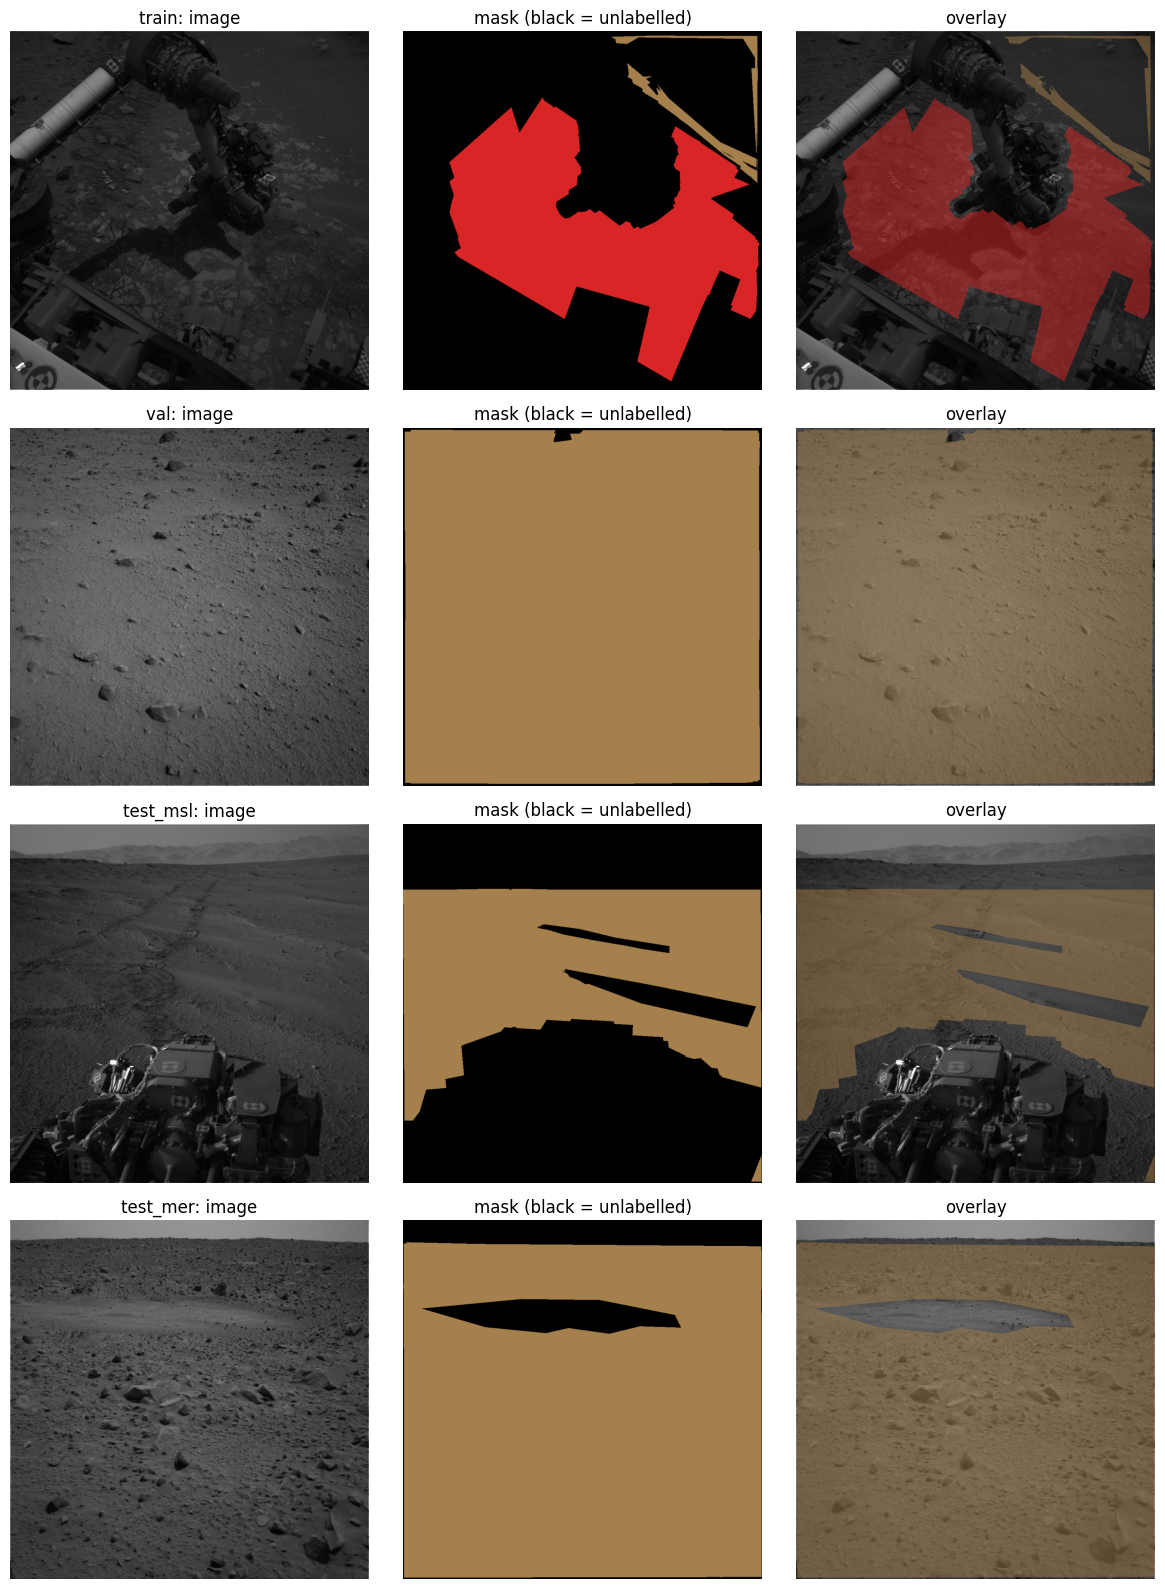

In [ ]:
# CELL B — eyeball real pairs
import io, matplotlib.pyplot as plt
from PIL import Image
print(z.read(ROOT + "label_keys.json").decode()[:1000])

pal = {0: (0.65, 0.5, 0.3), 1: (0.85, 0.15, 0.15), 2: (0.95, 0.85, 0.2), 3: (0.2, 0.4, 0.95)}
def colour(m):
    out = np.zeros((*m.shape, 3))
    for k, c in pal.items(): out[m == k] = c
    return out

fig, ax = plt.subplots(4, 3, figsize=(12, 16))
for r, (nm, d) in enumerate([("train", train_clean), ("val", val), ("test_msl", test_msl), ("test_mer", test_mer)]):
    row = d.sample(1, random_state=1).iloc[0]
    img = Image.open(io.BytesIO(z.read(ROOT + row["image_path"])))
    m = np.array(Image.open(io.BytesIO(z.read(ROOT + row["label_path"]))))
    print(nm, "| image mode/size:", img.mode, img.size, "| mask unique:", np.unique(m))
    g = np.array(img.convert("L")) / 255.0
    ov = np.stack([g] * 3, -1); lab = m != 255
    ov[lab] = 0.5 * ov[lab] + 0.5 * colour(m)[lab]
    ax[r, 0].imshow(g, cmap="gray"); ax[r, 0].set_title(f"{nm}: image")
    ax[r, 1].imshow(colour(m));      ax[r, 1].set_title("mask (black = unlabelled)")
    ax[r, 2].imshow(ov);             ax[r, 2].set_title("overlay")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{PROJ}/figures/split_check_pairs.png", dpi=90); plt.show()

train | labelled fraction: 0.987 | image: (1024, 1024) | mask values: [  0 255]
val | labelled fraction: 0.987 | image: (1024, 1024) | mask values: [  1 255]
test_msl | labelled fraction: 0.992 | image: (1024, 1024) | mask values: [  2 255]
test_mer | labelled fraction: 0.987 | image: (1024, 1024) | mask values: [  0 255]


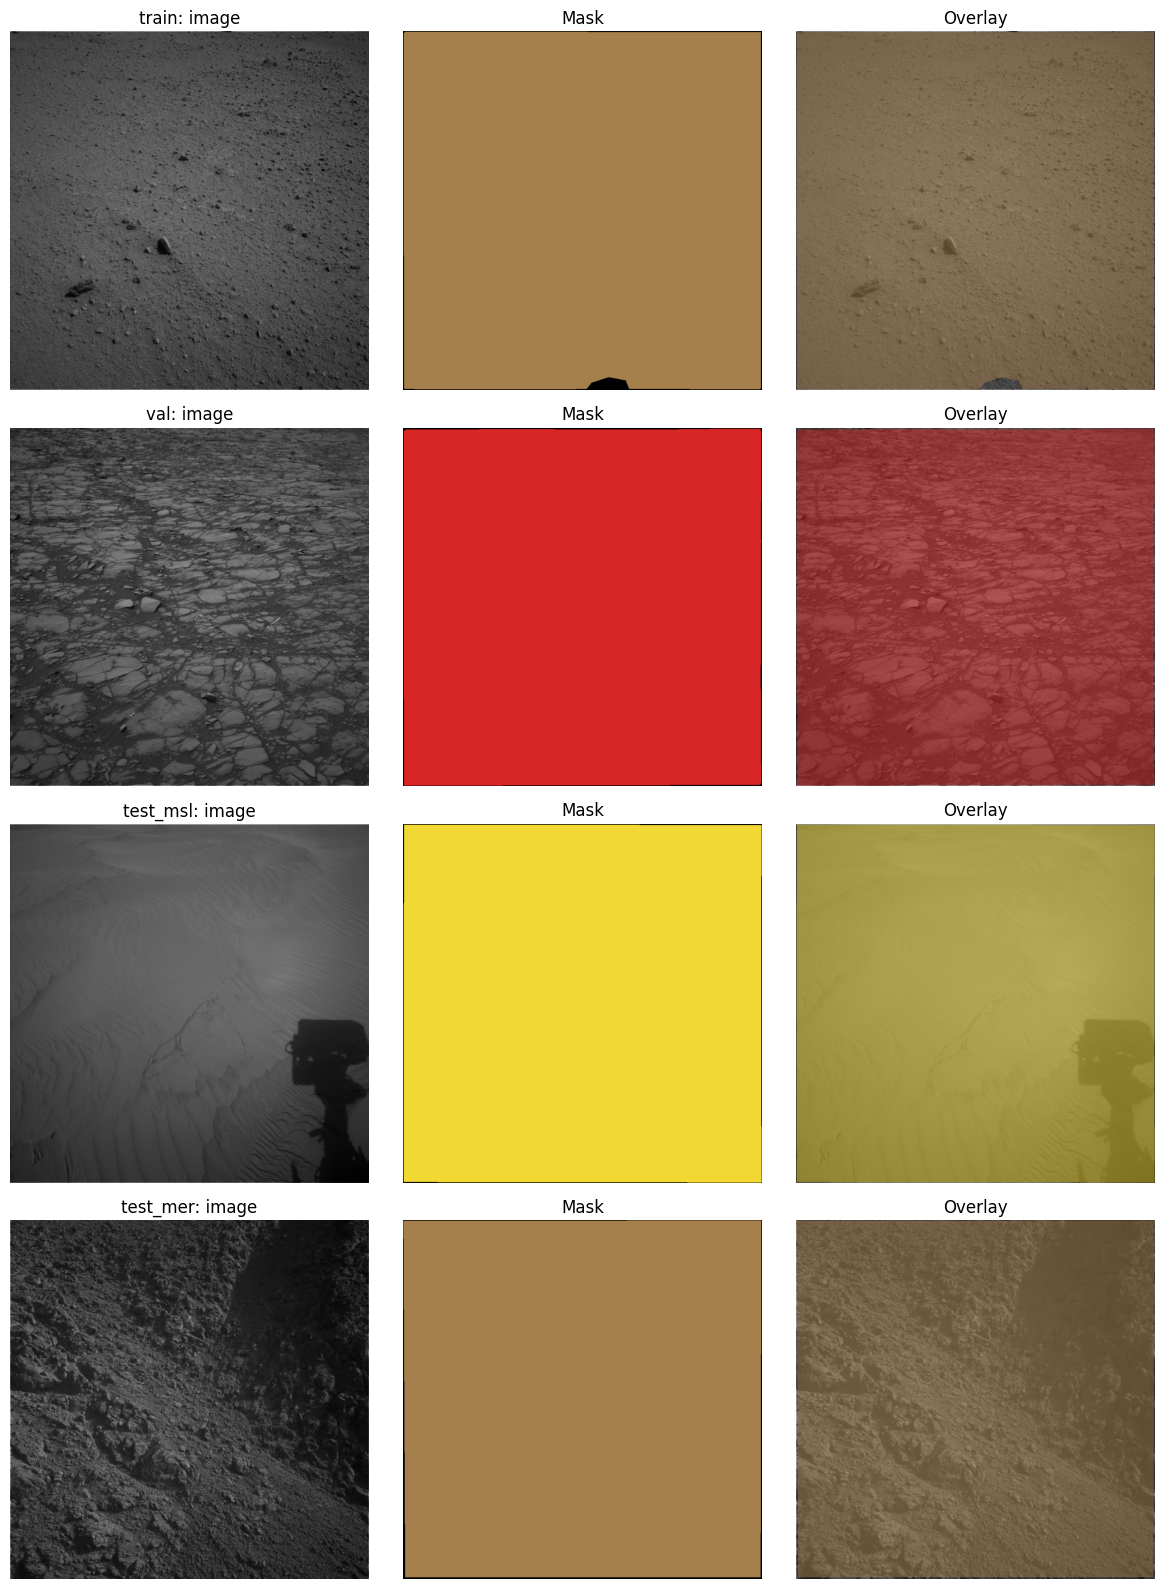

In [ ]:
# CELL B2 — inspect representative image-mask pairs

import io
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

datasets = [
    ("train", train_clean),
    ("val", val_clean),
    ("test_msl", test_msl),
    ("test_mer", test_mer)
]

fig, ax = plt.subplots(4, 3, figsize=(12, 16))

for r, (nm, d) in enumerate(datasets):
    row = d.sort_values("labeled_frac", ascending=False).iloc[0]

    img = Image.open(io.BytesIO(z.read(ROOT + row["image_path"])))
    m = np.array(Image.open(io.BytesIO(z.read(ROOT + row["label_path"]))))

    print(
        nm,
        "| labelled fraction:", round(row["labeled_frac"], 3),
        "| image:", img.size,
        "| mask values:", np.unique(m)
    )

    g = np.array(img.convert("L")) / 255.0
    overlay = np.stack([g] * 3, axis=-1)
    labelled = m != 255
    overlay[labelled] = (
        0.5 * overlay[labelled] + 0.5 * colour(m)[labelled]
    )

    ax[r, 0].imshow(g, cmap="gray")
    ax[r, 0].set_title(f"{nm}: image")

    ax[r, 1].imshow(colour(m))
    ax[r, 1].set_title("Mask")

    ax[r, 2].imshow(overlay)
    ax[r, 2].set_title("Overlay")

    for a in ax[r]:
        a.axis("off")

plt.tight_layout()
plt.show()

train big rock | mask values: [  1   2   3 255] | big-rock fraction: 0.7099
MER big rock | mask values: [  0   1   2   3 255] | big-rock fraction: 0.3966
MSL mixed | mask values: [  0   1   2 255] | big-rock fraction: 0.0
MER mixed | mask values: [  0   1   2 255] | big-rock fraction: 0.0


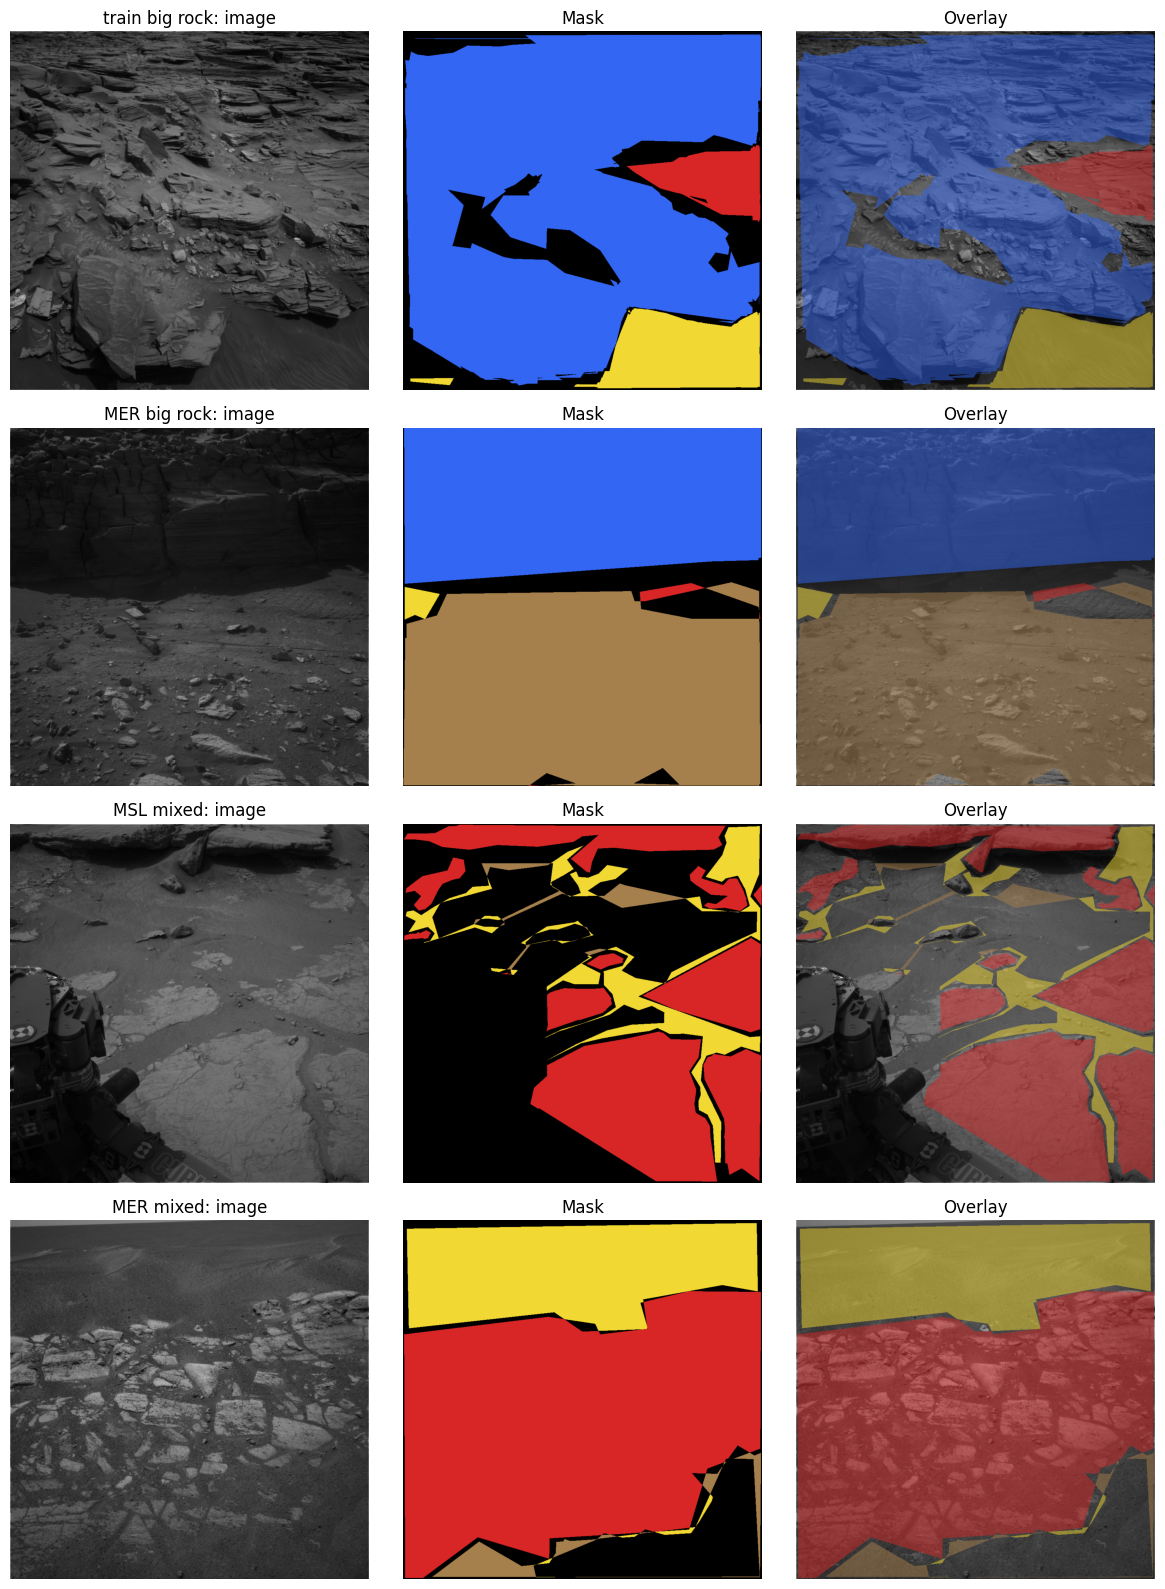

In [ ]:
# CELL B3 — inspect big rock and mixed-class scenes

def pick_bigrock(d, name):
    candidates = d[d["class_3"] > 0]

    if len(candidates) == 0:
        print(f"No big-rock-labelled image found in {name}")
        return None

    return candidates.sort_values(
        "class_3", ascending=False
    ).iloc[0]


def pick_mixed(d, name):
    shares = d[CC].div(d[CC].sum(axis=1).replace(0, np.nan), axis=0)
    candidates = d[shares.max(axis=1) < 0.8]

    if len(candidates) == 0:
        print(f"No suitable mixed image found in {name}")
        return None

    return candidates.iloc[0]


jobs = [
    ("train big rock", pick_bigrock(train_clean, "train")),
    ("MER big rock", pick_bigrock(test_mer, "MER")),
    ("MSL mixed", pick_mixed(test_msl, "MSL")),
    ("MER mixed", pick_mixed(test_mer, "MER"))
]

jobs = [(name, row) for name, row in jobs if row is not None]

fig, ax = plt.subplots(len(jobs), 3, figsize=(12, 4 * len(jobs)))

if len(jobs) == 1:
    ax = np.array([ax])

for r, (name, row) in enumerate(jobs):
    img = Image.open(io.BytesIO(z.read(ROOT + row["image_path"])))
    m = np.array(Image.open(io.BytesIO(z.read(ROOT + row["label_path"]))))

    print(name, "| mask values:", np.unique(m),
          "| big-rock fraction:", round(float((m == 3).mean()), 4))

    g = np.array(img.convert("L")) / 255.0
    ov = np.stack([g] * 3, axis=-1)
    labelled = m != 255
    ov[labelled] = 0.5 * ov[labelled] + 0.5 * colour(m)[labelled]

    ax[r, 0].imshow(g, cmap="gray")
    ax[r, 0].set_title(f"{name}: image")

    ax[r, 1].imshow(colour(m))
    ax[r, 1].set_title("Mask")

    ax[r, 2].imshow(ov)
    ax[r, 2].set_title("Overlay")

    for a in ax[r]:
        a.axis("off")

plt.tight_layout()
plt.savefig(f"{PROJ}/figures/split_check_bigrock_mixed.png", dpi=70)
plt.show()

In [ ]:
save_to_laptop(
    [f"{PROJ}/splits", f"{PROJ}/figures"],
    "backup_02_splits_and_visual_checks"
)

Created: /content/backup_02_splits_and_visual_checks.zip
Size: 2.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CELL C — memory and speed, 512 vs 1024, T4
import torch, time, gc
from transformers import SegformerForSemanticSegmentation

def trial(res, bs, iters=5):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=4).cuda().train()
    opt = torch.optim.AdamW(model.parameters(), lr=6e-5)
    scaler = torch.amp.GradScaler()
    x = torch.randn(bs, 3, res, res, device="cuda")
    y = torch.randint(0, 4, (bs, res, res), device="cuda")
    try:
        for i in range(iters + 1):
            if i == 1: torch.cuda.synchronize(); t = time.time()
            with torch.autocast("cuda", dtype=torch.float16):
                loss = model(pixel_values=x, labels=y).loss
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
        torch.cuda.synchronize(); spi = (time.time() - t) / iters / bs
        r = dict(res=res, bs=bs, peak_GB=round(torch.cuda.max_memory_allocated()/2**30, 2), sec_per_img=round(spi, 3), ok=True)
    except torch.cuda.OutOfMemoryError:
        r = dict(res=res, bs=bs, peak_GB=None, sec_per_img=None, ok=False)
    del model, opt, x, y; gc.collect(); torch.cuda.empty_cache()
    return r

N = len(train_clean)
rows = [trial(r, b) for r, b in [(512, 8), (512, 16), (1024, 1), (1024, 2), (1024, 4)]]
res_df = pd.DataFrame(rows)
res_df["min_per_epoch"] = (res_df["sec_per_img"] * N / 60).round(1)
res_df["hrs_3seeds_20ep"] = (res_df["min_per_epoch"] * 20 * 3 / 60).round(1)
print(res_df)
res_df.to_csv(f"{PROJ}/results/feasibility_512_vs_1024.csv", index=False)

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_var                      

... (8 outputs left out)

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_var                      

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                                     | Status     | 
--------------------------------------------------------+------------+-
classifier.weight                                       | UNEXPECTED | 
classifier.bias                                         | UNEXPECTED | 
decode_head.classifier.weight                           | MISSING    | 
decode_head.batch_norm.num_batches_tracked              | MISSING    | 
decode_head.batch_norm.bias                             | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                           | MISSING    | 
decode_head.linear_projections.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.running_mean                     | MISSING    | 
decode_head.linear_fuse.weight                          | MISSING    | 
decode_head.batch_norm.running_var                      

    res  bs  peak_GB  sec_per_img    ok  min_per_epoch  hrs_3seeds_20ep
0   512   8     2.23        0.018  True            1.9              1.9
1   512  16     4.38        0.015  True            1.6              1.6
2  1024   1     1.31        0.143  True           15.4             15.4
3  1024   2     2.23        0.082  True            8.8              8.8
4  1024   4     4.38        0.075  True            8.1              8.1


In [ ]:
import os

PROJ = "/content/mars_compression"

for folder in [
    "splits",
    "figures",
    "results",
    "logs",
    "checkpoints/legacy_epoch14",
    "checkpoints/FROZEN_baseline"
]:
    path = os.path.join(PROJ, folder)
    print(f"\n--- {folder} ---")

    if not os.path.exists(path):
        print("NOT FOUND")
        continue

    for root, dirs, files in os.walk(path):
        for name in files:
            full = os.path.join(root, name)
            print(
                os.path.relpath(full, PROJ),
                "|",
                round(os.path.getsize(full) / (1024 * 1024), 2),
                "MB"
            )


--- splits ---
splits/split_v2_test_msl.csv | 0.07 MB
splits/split_v2_test_mer.csv | 0.04 MB
splits/split_v2b_val.csv | 0.13 MB
splits/split_v2_train.csv | 2.12 MB
splits/split_rule_v2b.json | 0.0 MB
splits/split_v2b_test_msl.csv | 0.07 MB
splits/split_v2b_test_mer.csv | 0.04 MB
splits/split_rule_v2.json | 0.0 MB
splits/index_v2_with_stats.csv | 3.67 MB
splits/split_v2_val.csv | 0.27 MB
splits/split_v2b_train.csv | 1.16 MB

--- figures ---
figures/split_check_pairs.png | 0.9 MB
figures/split_check_bigrock_mixed.png | 0.66 MB

--- results ---
results/feasibility_512_vs_1024.csv | 0.0 MB

--- logs ---
logs/pip_freeze_colab.txt | 0.01 MB

--- checkpoints/legacy_epoch14 ---
checkpoints/legacy_epoch14/best_msl.pt | 14.25 MB
checkpoints/legacy_epoch14/baseline_results.csv | 0.0 MB
checkpoints/legacy_epoch14/train_log.csv | 0.0 MB

--- checkpoints/FROZEN_baseline ---


In [ ]:
import os
import zipfile

PROJ = "/content/mars_compression"
ZIP_PATH = "/content/backup_03_current_project_state.zip"

folders = [
    "splits",
    "figures",
    "results",
    "logs",
    "checkpoints/legacy_epoch14"
]

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in folders:
        full_folder = os.path.join(PROJ, folder)

        for root, dirs, files in os.walk(full_folder):
            for file in files:
                full_path = os.path.join(root, file)
                arcname = os.path.relpath(full_path, PROJ)
                z.write(full_path, arcname)

print("Created:", ZIP_PATH)
print("Size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")

from google.colab import files
files.download(ZIP_PATH)

Created: /content/backup_03_current_project_state.zip
Size: 15.98 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

archive = "/content/ai4mars-dataset-merged-0.6.zip"

print("Exists:", os.path.exists(archive))

if os.path.exists(archive):
    print("Size (GiB):", round(os.path.getsize(archive) / (1024**3), 2))

Exists: True
Size (GiB): 15.12


In [ ]:
from google.colab import files
files.download("/content/ai4mars-dataset-merged-0.6.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import torch

archive = "/content/ai4mars-dataset-merged-0.6.zip"

print("Archive exists:", os.path.exists(archive))
if os.path.exists(archive):
    print("Archive size (GiB):", round(os.path.getsize(archive)/1024**3, 2))

print("Project folder exists:", os.path.exists("/content/mars_compression"))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

Archive exists: True
Archive size (GiB): 15.12
Project folder exists: True
GPU: Tesla T4


In [ ]:
import os
import re
import pandas as pd

# Load the existing dataset index
idx = pd.read_csv(f"{PROJ}/splits/index_v2_with_stats.csv")

# Select a few MSL images
sample = idx[idx["set"] == "msl_crowd_train"].sample(
    10, random_state=42
)

print("SAMPLE IMAGE FILENAMES\n")

for path in sample["image_path"]:
    name = os.path.basename(path)

    timestamp = re.search(r"_(\d{9})EDR", name)
    frame = re.search(r"_F(\d{4})", name)

    print("Filename:", name)
    print("Extracted timestamp:", timestamp.group(1) if timestamp else "Not found")
    print("Extracted F value:", frame.group(1) if frame else "Not found")
    print("-" * 80)

SAMPLE IMAGE FILENAMES

Filename: NLB_484853663EDR_F0480000NCAM00264M1.JPG
Extracted timestamp: 484853663
Extracted F value: 0480
--------------------------------------------------------------------------------
Filename: NLB_489117705EDR_F0481600NCAM00320M1.JPG
Extracted timestamp: 489117705
Extracted F value: 0481
--------------------------------------------------------------------------------
Filename: NLB_538107057EDR_F0601422NCAM00207M1.JPG
Extracted timestamp: 538107057
Extracted F value: 0601
--------------------------------------------------------------------------------
Filename: NLB_615262438EDR_F0761546NCAM00385M1.JPG
Extracted timestamp: 615262438
Extracted F value: 0761
--------------------------------------------------------------------------------
Filename: NLB_576828635EDR_F0691738NCAM00385M1.JPG
Extracted timestamp: 576828635
Extracted F value: 0691
--------------------------------------------------------------------------------
Filename: NLB_625478979EDR_F0770910NCAM00

In [ ]:
import numpy as np
import pandas as pd

# Extract SCLK from every indexed image filename
idx = pd.read_csv(f"{PROJ}/splits/index_v2_with_stats.csv")

idx["sclk"] = (
    idx["image_path"]
    .str.extract(r"_(\d{9})EDR")[0]
    .astype(float)
)

# Convert the timestamp range into approximate Martian sols
SOL = 88775

sclk_min = idx["sclk"].min()
sclk_max = idx["sclk"].max()

print("Total indexed images:", len(idx))
print("Missing timestamps:", idx["sclk"].isna().sum())

print("\nSCLK RANGE")
print("Minimum:", sclk_min)
print("Maximum:", sclk_max)
print("Difference in seconds:", sclk_max - sclk_min)
print("Approximate difference in sols:", round((sclk_max-sclk_min)/SOL, 2))

print("\nSAMPLE TIMESTAMPS")
print(idx[["image_path", "sclk"]].sample(10, random_state=42).to_string(index=False))

Total indexed images: 17642
Missing timestamps: 612

SCLK RANGE
Minimum: 397586934.0
Maximum: 626441991.0
Difference in seconds: 228855057.0
Approximate difference in sols: 2577.92

SAMPLE TIMESTAMPS
                                                  image_path        sclk
             mer/images/test/1n423368923effc0nsp0712l0m1.JPG         NaN
msl/ncam/images/edr/NLB_537500718EDR_F0600684NCAM07813M1.JPG 537500718.0
msl/ncam/images/edr/NLB_455204600EDR_F0340286NCAM00298M1.JPG 455204600.0
msl/ncam/images/edr/NLA_602664178EDR_F0732958NCAM00271M1.JPG 602664178.0
msl/ncam/images/edr/NLA_399621461EDR_F0030308NCAM00404M1.JPG 399621461.0
msl/ncam/images/edr/NLB_521604839EDR_F0551864NCAM00258M1.JPG 521604839.0
msl/ncam/images/edr/NLB_455114927EDR_F0340286NCAM00297M1.JPG 455114927.0
msl/ncam/images/edr/NLB_449694391EDR_F0301254NCAM00251M1.JPG 449694391.0
msl/ncam/images/edr/NLB_512555120EDR_F0532644NCAM00264M1.JPG 512555120.0
msl/ncam/images/edr/NLB_465576850EDR_F0421020NCAM00223M1.JPG 465576850

In [ ]:
# Check timestamp coverage by dataset subset

idx["sclk"] = pd.to_numeric(idx["sclk"], errors="coerce")

print("TIMESTAMP COVERAGE BY SET")
coverage = (
    idx.groupby(["rover", "set"])
    .agg(
        total_images=("image_path", "size"),
        valid_timestamps=("sclk", "count"),
        missing_timestamps=("sclk", lambda x: x.isna().sum()),
        min_sclk=("sclk", "min"),
        max_sclk=("sclk", "max")
    )
    .reset_index()
)

print(coverage.to_string(index=False))

print("\nMSL TIMESTAMP CHECK")
msl = idx[idx["rover"].str.lower() == "msl"].copy()

print("Total MSL images:", len(msl))
print("Missing MSL timestamps:", msl["sclk"].isna().sum())
print("Unique MSL timestamps:", msl["sclk"].nunique())
print("Duplicate timestamp rows:", msl["sclk"].duplicated().sum())

TIMESTAMP COVERAGE BY SET
rover             set  total_images  valid_timestamps  missing_timestamps    min_sclk    max_sclk
  mer   mer_gold_min1           204                 0                 204         NaN         NaN
  mer   mer_gold_min2           204                 0                 204         NaN         NaN
  mer   mer_gold_min3           204                 0                 204         NaN         NaN
  msl msl_crowd_train         16064             16064                   0 397586934.0 626441991.0
  msl   msl_gold_min1           322               322                   0 409036068.0 613584326.0
  msl   msl_gold_min2           322               322                   0 409036068.0 613584326.0
  msl   msl_gold_min3           322               322                   0 409036068.0 613584326.0

MSL TIMESTAMP CHECK
Total MSL images: 17030
Missing MSL timestamps: 0
Unique MSL timestamps: 16349
Duplicate timestamp rows: 681


In [ ]:
# Inspect duplicate MSL timestamps and cross-subset overlap

msl = idx[idx["rover"].str.lower() == "msl"].copy()

# Count images sharing each timestamp
timestamp_groups = (
    msl.groupby("sclk")
    .agg(
        image_count=("image_path", "size"),
        subsets=("set", "nunique"),
        subset_names=("set", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

duplicates = timestamp_groups[timestamp_groups["image_count"] > 1]

print("DUPLICATE TIMESTAMP SUMMARY")
print("Timestamps with multiple images:", len(duplicates))
print("Images belonging to duplicate groups:", duplicates["image_count"].sum())
print("Maximum images at one timestamp:", timestamp_groups["image_count"].max())

print("\nTIMESTAMPS SHARED ACROSS SUBSETS")
shared = timestamp_groups[timestamp_groups["subsets"] > 1]
print("Timestamps appearing in multiple subsets:", len(shared))
print(shared.head(15).to_string(index=False))

print("\nCROWD TRAIN / GOLD MIN1 OVERLAP")
crowd_times = set(msl.loc[msl["set"] == "msl_crowd_train", "sclk"])
gold_times = set(msl.loc[msl["set"] == "msl_gold_min1", "sclk"])
overlap = crowd_times.intersection(gold_times)

print("Shared timestamps:", len(overlap))
print("Crowd train images at shared timestamps:",
      msl[(msl["set"] == "msl_crowd_train") & (msl["sclk"].isin(overlap))].shape[0])
print("Gold min1 images at shared timestamps:",
      msl[(msl["set"] == "msl_gold_min1") & (msl["sclk"].isin(overlap))].shape[0])

DUPLICATE TIMESTAMP SUMMARY
Timestamps with multiple images: 359
Images belonging to duplicate groups: 1040
Maximum images at one timestamp: 3

TIMESTAMPS SHARED ACROSS SUBSETS
Timestamps appearing in multiple subsets: 322
       sclk  image_count  subsets                                subset_names
409036068.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
409036116.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
409036860.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
409036993.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
409037112.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
427501146.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
427503509.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
427503571.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_min3
428295522.0            3        3 msl_gold_min1, msl_gold_min2, msl_gold_mi

In [ ]:
import numpy as np

SOL_SECONDS = 88775

crowd = idx[idx["set"] == "msl_crowd_train"].copy()
gold = idx[idx["set"] == "msl_gold_min1"].copy()

train_times = np.sort(crowd["sclk"].dropna().unique())
test_times = np.sort(gold["sclk"].dropna().unique())

# For every training timestamp, find the nearest test timestamp
positions = np.searchsorted(test_times, train_times)

left_idx = np.clip(positions - 1, 0, len(test_times) - 1)
right_idx = np.clip(positions, 0, len(test_times) - 1)

nearest_seconds = np.minimum(
    np.abs(train_times - test_times[left_idx]),
    np.abs(train_times - test_times[right_idx])
)

nearest_sols = nearest_seconds / SOL_SECONDS

print("TEMPORAL DISTANCE: CROWD TRAIN TO MSL GOLD TEST")
print("Unique training timestamps:", len(train_times))
print("Unique test timestamps:", len(test_times))

print("\nNearest-gap statistics (in sols)")
for percentile in [0, 10, 25, 50, 75, 90, 100]:
    print(f"{percentile:>3}th percentile: {np.percentile(nearest_sols, percentile):.3f}")

print("\nTraining timestamps within:")
for buffer in [1, 3, 5, 10]:
    count = np.sum(nearest_sols <= buffer)
    print(f"{buffer:>2} sols: {count:>5} / {len(train_times)} "
          f"({100 * count / len(train_times):.2f}%)")

TEMPORAL DISTANCE: CROWD TRAIN TO MSL GOLD TEST
Unique training timestamps: 16027
Unique test timestamps: 322

Nearest-gap statistics (in sols)
  0th percentile: 0.718
 10th percentile: 2.096
 25th percentile: 5.937
 50th percentile: 15.015
 75th percentile: 34.016
 90th percentile: 86.029
100th percentile: 160.952

Training timestamps within:
 1 sols:   463 / 16027 (2.89%)
 3 sols:  2031 / 16027 (12.67%)
 5 sols:  3545 / 16027 (22.12%)
10 sols:  6151 / 16027 (38.38%)


In [ ]:
SOL_SECONDS = 88775

# Original training candidates: crowd images with at least 30% labelled pixels
pool = idx[
    (idx["set"] == "msl_crowd_train") &
    (idx["labeled_frac"] >= 0.30)
].copy()

gold = idx[idx["set"] == "msl_gold_min1"].copy()

test_times = np.sort(gold["sclk"].dropna().unique())
train_times = pool["sclk"].to_numpy()

# Find nearest test timestamp for every candidate training image
positions = np.searchsorted(test_times, train_times)

left_idx = np.clip(positions - 1, 0, len(test_times) - 1)
right_idx = np.clip(positions, 0, len(test_times) - 1)

nearest_seconds = np.minimum(
    np.abs(train_times - test_times[left_idx]),
    np.abs(train_times - test_times[right_idx])
)

pool["nearest_test_gap_sols"] = nearest_seconds / SOL_SECONDS

print("ELIGIBLE TRAINING POOL:", len(pool))

for buffer in [1, 3, 5, 10]:
    remaining = pool[pool["nearest_test_gap_sols"] > buffer]
    removed = len(pool) - len(remaining)

    print(f"\n--- {buffer}-SOL BUFFER ---")
    print("Remaining images:", len(remaining))
    print("Removed images:", removed)
    print("Percentage removed:", round(100 * removed / len(pool), 2))

    print("Class pixel proportions:")
    total = sum(remaining[f"class_{i}"].sum() for i in range(4))
    for i, name in enumerate(["soil", "bedrock", "sand", "big rock"]):
        share = remaining[f"class_{i}"].sum() / total if total else 0
        print(f"  {name}: {share:.4f}")

ELIGIBLE TRAINING POOL: 13429

--- 1-SOL BUFFER ---
Remaining images: 13026
Removed images: 403
Percentage removed: 3.0
Class pixel proportions:
  soil: 0.3711
  bedrock: 0.5039
  sand: 0.1165
  big rock: 0.0085

--- 3-SOL BUFFER ---
Remaining images: 11674
Removed images: 1755
Percentage removed: 13.07
Class pixel proportions:
  soil: 0.3578
  bedrock: 0.5209
  sand: 0.1127
  big rock: 0.0086

--- 5-SOL BUFFER ---
Remaining images: 10423
Removed images: 3006
Percentage removed: 22.38
Class pixel proportions:
  soil: 0.3444
  bedrock: 0.5338
  sand: 0.1128
  big rock: 0.0090

--- 10-SOL BUFFER ---
Remaining images: 8223
Removed images: 5206
Percentage removed: 38.77
Class pixel proportions:
  soil: 0.3311
  bedrock: 0.5483
  sand: 0.1110
  big rock: 0.0095


In [ ]:
# STEP 1 — build CANDIDATE split "v3c" (time-based buffers) and compare it with v2b.
import os, json, numpy as np, pandas as pd

SOL = 88775                       # seconds in one Mars day (sol)
TRAIN_MIN, TEST_MIN = 0.30, 0.10  # same labelled-pixel thresholds as before
BUF_TEST, BUF_VAL = 3, 3          # buffers measured in real sols (days), from timestamps
VAL_BLOCK, VAL_FRAC, SEED = 5, 0.10, 0
CC = ["class_0", "class_1", "class_2", "class_3"]

def add_time(d):
    d = d.copy()
    name = d["image_path"].map(os.path.basename)
    d["sclk"] = name.str.extract(r"_(\d{9})EDR")[0].astype(float)   # timestamp
    d["F"]    = name.str.extract(r"_F(\d{4})")[0].astype(float)     # site/drive counter
    return d

def gap_sols(x, ref):
    ref = np.sort(ref); i = np.searchsorted(ref, x)
    lo = np.abs(x - ref[np.clip(i - 1, 0, len(ref) - 1)])
    hi = np.abs(x - ref[np.clip(i,     0, len(ref) - 1)])
    return np.minimum(lo, hi) / SOL

def share(d):
    c = d[CC].sum(); return (c / c.sum()).round(3).tolist()

idx  = add_time(pd.read_csv(f"{PROJ}/splits/index_v2_with_stats.csv"))
pool = idx[(idx["set"] == "msl_crowd_train") & (idx["labeled_frac"] >= TRAIN_MIN)].copy()
test = idx[(idx["set"] == "msl_gold_min1")   & (idx["labeled_frac"] >= TEST_MIN)].copy()
print("pool:", len(pool), "| MSL test:", len(test))

# 1) drop training candidates closer than BUF_TEST sols to any expert test frame
pool["gap_test"] = gap_sols(pool["sclk"].values, test["sclk"].values)
pool_t = pool[pool["gap_test"] > BUF_TEST].copy()

# 2) validation = whole 5-sol time blocks spread over the mission (~10% of frames)
pool_t["blk"] = ((pool_t["sclk"] - pool_t["sclk"].min()) // (VAL_BLOCK * SOL)).astype(int)
rng = np.random.RandomState(SEED)
blocks = pool_t["blk"].unique(); rng.shuffle(blocks)
vb, n = [], 0
for b in blocks:
    if n >= VAL_FRAC * len(pool_t): break
    vb.append(int(b)); n += int((pool_t["blk"] == b).sum())
val  = pool_t[pool_t["blk"].isin(vb)].copy()

# 3) train = the rest, minus anything closer than BUF_VAL sols to a validation frame
rest = pool_t[~pool_t["blk"].isin(vb)].copy()
train = rest[gap_sols(rest["sclk"].values, val["sclk"].values) > BUF_VAL].copy()

mer = pd.read_csv(f"{PROJ}/splits/split_v2b_test_mer.csv")   # MER test unchanged

# ---- compare v2b (old) with v3c (new)
v2b = {k: add_time(pd.read_csv(f"{PROJ}/splits/split_v2b_{k}.csv")) for k in ["train", "val", "test_msl"]}
rows = []
for name, tr, va, te in [("v2b", v2b["train"], v2b["val"], v2b["test_msl"]), ("v3c", train, val, test)]:
    rows.append(dict(split=name, train=len(tr), val=len(va),
        min_gap_train_test=round(gap_sols(tr["sclk"].values, te["sclk"].values).min(), 2),
        min_gap_val_test=round(gap_sols(va["sclk"].values, te["sclk"].values).min(), 2),
        min_gap_train_val=round(gap_sols(tr["sclk"].values, va["sclk"].values).min(), 2),
        train_within_10_sols_of_test=int((gap_sols(tr["sclk"].values, te["sclk"].values) <= 10).sum()),
        val_distinct_sites=int((va["F"] // 10).nunique())))
print("\nCOMPARISON (gaps are in real sols):")
print(pd.DataFrame(rows).to_string(index=False))
print("\nclass shares [soil, bedrock, sand, big rock]")
for nm, d in [("v2b train", v2b["train"]), ("v2b val", v2b["val"]), ("v3c train", train), ("v3c val", val), ("test_msl", test)]:
    print(f"  {nm:10s}", share(d))
print("\nv3c val blocks used:", len(vb), "| val frames:", len(val))

# ---- save candidate files (new names only)
cols = ["image_path", "label_path", "labeled_frac", "sclk", "F"] + CC
for nm, d in [("train", train), ("val", val), ("test_msl", test)]:
    d[cols].to_csv(f"{PROJ}/splits/split_v3c_{nm}.csv", index=False)
mer.to_csv(f"{PROJ}/splits/split_v3c_test_mer.csv", index=False)
json.dump(dict(status="CANDIDATE", sol_seconds=SOL, buffer_test_sols=BUF_TEST, buffer_val_sols=BUF_VAL,
               val_block_sols=VAL_BLOCK, val_frac=VAL_FRAC, seed=SEED, train_min_labeled=TRAIN_MIN,
               test_min_labeled=TEST_MIN, note="F#### is a site/drive counter, NOT a sol; buffers use SCLK time",
               n=dict(train=len(train), val=len(val), test_msl=len(test), test_mer=len(mer))),
          open(f"{PROJ}/splits/split_rule_v3c.json", "w"), indent=1)
print("\nsaved split_v3c_*.csv + split_rule_v3c.json")

pool: 13429 | MSL test: 311

COMPARISON (gaps are in real sols):
split  train  val  min_gap_train_test  min_gap_val_test  min_gap_train_val  train_within_10_sols_of_test  val_distinct_sites
  v2b   6457  746                1.09              4.97               0.01                           891                   5
  v3c   9836 1168                3.00              3.05               3.00                          2958                  29

class shares [soil, bedrock, sand, big rock]
  v2b train  [0.394, 0.481, 0.115, 0.011]
  v2b val    [0.288, 0.659, 0.042, 0.012]
  v3c train  [0.389, 0.505, 0.098, 0.007]
  v3c val    [0.165, 0.602, 0.216, 0.017]
  test_msl   [0.458, 0.309, 0.231, 0.002]

v3c val blocks used: 49 | val frames: 1168

saved split_v3c_*.csv + split_rule_v3c.json


In [ ]:
# STEP 2 — choose the validation seed by a rule fixed IN ADVANCE, then FREEZE split v3.
# Rule: among seeds 0-19, pick the seed whose validation class mix is closest (L1 distance)
# to the TRAINING class mix. The test-set class mix is never used.
import os, json, hashlib, numpy as np, pandas as pd

SOL = 88775
TRAIN_MIN, TEST_MIN = 0.30, 0.10
BUF_TEST, BUF_VAL, VAL_BLOCK, VAL_FRAC = 3, 3, 5, 0.10
SEEDS = range(20)
CC = ["class_0", "class_1", "class_2", "class_3"]

def add_time(d):
    d = d.copy(); name = d["image_path"].map(os.path.basename)
    d["sclk"] = name.str.extract(r"_(\d{9})EDR")[0].astype(float)
    d["F"]    = name.str.extract(r"_F(\d{4})")[0].astype(float)
    return d

def gap_sols(x, ref):
    ref = np.sort(ref); i = np.searchsorted(ref, x)
    lo = np.abs(x - ref[np.clip(i - 1, 0, len(ref) - 1)])
    hi = np.abs(x - ref[np.clip(i,     0, len(ref) - 1)])
    return np.minimum(lo, hi) / SOL

def share(d):
    c = d[CC].sum(); return (c / c.sum()).round(3).tolist()

idx  = add_time(pd.read_csv(f"{PROJ}/splits/index_v2_with_stats.csv"))
pool = idx[(idx["set"] == "msl_crowd_train") & (idx["labeled_frac"] >= TRAIN_MIN)].copy()
test = idx[(idx["set"] == "msl_gold_min1")   & (idx["labeled_frac"] >= TEST_MIN)].copy()
mer  = pd.read_csv(f"{PROJ}/splits/split_v2b_test_mer.csv")

pool = pool[gap_sols(pool["sclk"].values, test["sclk"].values) > BUF_TEST].copy()
pool["blk"] = ((pool["sclk"] - pool["sclk"].min()) // (VAL_BLOCK * SOL)).astype(int)

def make_split(seed):
    rng = np.random.RandomState(seed)
    blocks = pool["blk"].unique(); rng.shuffle(blocks)
    vb, n = [], 0
    for b in blocks:
        if n >= VAL_FRAC * len(pool): break
        vb.append(int(b)); n += int((pool["blk"] == b).sum())
    val  = pool[pool["blk"].isin(vb)].copy()
    rest = pool[~pool["blk"].isin(vb)]
    train = rest[gap_sols(rest["sclk"].values, val["sclk"].values) > BUF_VAL].copy()
    return val, train, len(vb)

rows, cache = [], {}
for sd in SEEDS:
    val, train, nb = make_split(sd)
    l1 = float(np.abs(np.array(share(train)) - np.array(share(val))).sum())
    rows.append(dict(seed=sd, train=len(train), val=len(val), val_blocks=nb, L1_val_vs_train=round(l1, 3),
                     val_imgs_with_bigrock=int((val["class_3"] > 0).sum())))
    cache[sd] = (val, train, nb)
res = pd.DataFrame(rows).sort_values("L1_val_vs_train")
print("SEED SEARCH (lower L1 = validation mix closer to training mix)")
print(res.head(6).to_string(index=False))
print("... worst seed L1:", res["L1_val_vs_train"].max())
best = int(res.iloc[0]["seed"])
val, train, nb = cache[best]
print(f"\nCHOSEN SEED: {best}")

# ---- verification checks on the final files
sets = {"train": train, "val": val, "test_msl": test}
names = list(sets)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        assert not (set(sets[a]["image_path"]) & set(sets[b]["image_path"])), f"image overlap {a}/{b}"
        assert not (set(sets[a]["sclk"]) & set(sets[b]["sclk"])), f"timestamp overlap {a}/{b}"
        g = gap_sols(sets[a]["sclk"].values, sets[b]["sclk"].values).min()
        assert g >= 3.0, f"gap {a}/{b} = {g}"
        print(f"  min gap {a:8s} -> {b:8s}: {g:.2f} sols")
assert (train["labeled_frac"] >= TRAIN_MIN).all() and (val["labeled_frac"] >= TRAIN_MIN).all()
assert (test["labeled_frac"] >= TEST_MIN).all() and len(test) == 311 and len(mer) == 195
assert mer["image_path"].str.contains("mer/images/test/").all()
print("ALL CHECKS PASSED")

# ---- summary table
rows = []
for nm, d in [("train", train), ("val", val), ("test_msl", test), ("test_mer", mer)]:
    rows.append(dict(split=nm, n=len(d), mean_labeled=round(d["labeled_frac"].mean(), 3),
                     imgs_with_bigrock=int((d["class_3"] > 0).sum()),
                     soil_bed_sand_rock=share(d)))
print("\nFINAL SPLIT v3"); print(pd.DataFrame(rows).to_string(index=False))

# ---- freeze: write final files + manifest with checksums
cols = ["image_path", "label_path", "labeled_frac", "sclk", "F"] + CC
manifest = {}
for nm, d in [("train", train), ("val", val), ("test_msl", test)]:
    d[cols].to_csv(f"{PROJ}/splits/split_v3_{nm}.csv", index=False)
mer.to_csv(f"{PROJ}/splits/split_v3_test_mer.csv", index=False)
for nm in ["train", "val", "test_msl", "test_mer"]:
    p = f"{PROJ}/splits/split_v3_{nm}.csv"
    manifest[nm] = dict(rows=int(len(pd.read_csv(p))), md5=hashlib.md5(open(p, "rb").read()).hexdigest())
json.dump(dict(status="FROZEN", rule="val seed = min L1(val class mix, train class mix) over seeds 0-19; test mix never used",
               seed=best, buffer_test_sols=BUF_TEST, buffer_val_sols=BUF_VAL, val_block_sols=VAL_BLOCK,
               train_min_labeled=TRAIN_MIN, test_min_labeled=TEST_MIN, sol_seconds=SOL,
               note="F#### is a site/drive counter, NOT a sol; buffers use SCLK time", files=manifest),
          open(f"{PROJ}/splits/split_v3_FROZEN.json", "w"), indent=1)
print("\nsaved split_v3_{train,val,test_msl,test_mer}.csv + split_v3_FROZEN.json")

SEED SEARCH (lower L1 = validation mix closer to training mix)
 seed  train  val  val_blocks  L1_val_vs_train  val_imgs_with_bigrock
   11   9803 1192          39            0.032                    184
    8   9600 1170          44            0.069                    152
   17   9870 1186          39            0.069                    159
    2   9580 1172          45            0.074                    156
    4   9506 1193          44            0.086                    188
    5   9713 1189          43            0.096                    161
... worst seed L1: 0.449

CHOSEN SEED: 11
  min gap train    -> val     : 3.01 sols
  min gap train    -> test_msl: 3.00 sols
  min gap val      -> test_msl: 3.83 sols
ALL CHECKS PASSED

FINAL SPLIT v3
   split    n  mean_labeled  imgs_with_bigrock           soil_bed_sand_rock
   train 9803         0.631               1379  [0.363, 0.518, 0.11, 0.008]
     val 1192         0.622                184 [0.348, 0.531, 0.113, 0.009]
test_msl  311    

In [ ]:
save_to_laptop([f"{PROJ}/splits"], "save02_split_v3_frozen")

Created: /content/save02_split_v3_frozen.zip
Size: 2.05 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 3 — build the compact 512x512 PNG dataset from the FROZEN split v3 files.
# Images: grayscale, resized 1024->512 with BILINEAR (same as your legacy model), saved LOSSLESS (PNG).
# Masks : resized with NEAREST (labels stay 0/1/2/3/255), saved as PNG.
# Safe to re-run: files already built are skipped (resume after a disconnect).
import os, io, json, zipfile, threading, numpy as np, pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

ZIP  = "/content/ai4mars-dataset-merged-0.6.zip"
ROOT = "ai4mars-dataset-merged-0.6/"
S    = 512
OUT  = "/content/dataset_v3_512"
SPLITS = ["train", "val", "test_msl", "test_mer"]
assert os.path.exists(ZIP), "The 15 GB zip is no longer in /content (runtime was reset). Tell me and we will re-download it."

z, lock = zipfile.ZipFile(ZIP), threading.Lock()

def build_one(args):
    sp, image_path, label_path = args
    name = os.path.splitext(os.path.basename(image_path))[0]
    ip, mp = f"{sp}/img/{name}.png", f"{sp}/mask/{name}.png"
    if not (os.path.exists(f"{OUT}/{ip}") and os.path.exists(f"{OUT}/{mp}")):
        with lock:                                           # zip reads are not thread-safe
            ib, lb = z.read(ROOT + image_path), z.read(ROOT + label_path)
        im = Image.open(io.BytesIO(ib)).convert("L")
        mk = Image.open(io.BytesIO(lb))
        assert im.size == (1024, 1024) and mk.size == (1024, 1024), (image_path, im.size, mk.size)
        im.resize((S, S), Image.BILINEAR).save(f"{OUT}/{ip}")
        mk.resize((S, S), Image.NEAREST).save(f"{OUT}/{mp}")
    return ip, mp

for sp in SPLITS:
    d = pd.read_csv(f"{PROJ}/splits/split_v3_{sp}.csv")
    os.makedirs(f"{OUT}/{sp}/img", exist_ok=True); os.makedirs(f"{OUT}/{sp}/mask", exist_ok=True)
    with ThreadPoolExecutor(max_workers=2) as ex:
        paths = list(tqdm(ex.map(build_one, [(sp, a, b) for a, b in zip(d["image_path"], d["label_path"])]),
                          total=len(d), desc=sp))
    d["img_512"] = [p[0] for p in paths]; d["mask_512"] = [p[1] for p in paths]
    d.to_csv(f"{OUT}/{sp}.csv", index=False)

# ---------------- verification (reads every file back) ----------------
CC = ["class_0", "class_1", "class_2", "class_3"]
rows = []
for sp in SPLITS:
    d = pd.read_csv(f"{OUT}/{sp}.csv"); cnt = np.zeros(256); big = 0
    for ip, mp in zip(d["img_512"], d["mask_512"]):
        im, mk = Image.open(f"{OUT}/{ip}"), Image.open(f"{OUT}/{mp}")
        assert im.size == (S, S) and im.mode == "L" and mk.size == (S, S), (ip, im.size, im.mode, mk.size)
        c = np.bincount(np.array(mk).ravel(), minlength=256); cnt += c; big += int(c[3] > 0)
    lab = cnt[:4].sum(); bad = int(cnt.sum() - lab - cnt[255])
    s1024 = d[CC].sum() / d[CC].sum().sum()
    rows.append(dict(split=sp, n=len(d), bad_label_px=bad, imgs_with_bigrock_512=big,
                     share_512=[round(x, 3) for x in (cnt[:4] / lab)],
                     share_1024=[round(x, 3) for x in s1024],
                     max_abs_diff=round(float(np.abs(cnt[:4] / lab - s1024.values).max()), 4)))
print("\nVERIFICATION"); print(pd.DataFrame(rows).to_string(index=False))
json.dump(dict(size=S, image="grayscale L, BILINEAR 1024->512, PNG lossless", mask="NEAREST 1024->512, PNG",
               source_split="split_v3_*.csv (FROZEN)", ignore_label=255, classes=["soil", "bedrock", "sand", "big rock"]),
          open(f"{OUT}/preprocessing.json", "w"), indent=1)
import subprocess
print(subprocess.run(f"du -sh {OUT}/*", shell=True, capture_output=True, text=True).stdout)
print("DONE ->", OUT)

train:   0%|          | 0/9803 [00:00<?, ?it/s]

val:   0%|          | 0/1192 [00:00<?, ?it/s]

test_msl:   0%|          | 0/311 [00:00<?, ?it/s]

test_mer:   0%|          | 0/195 [00:00<?, ?it/s]


VERIFICATION
   split    n  bad_label_px  imgs_with_bigrock_512                    share_512                   share_1024  max_abs_diff
   train 9803             0                   1359  [0.363, 0.518, 0.11, 0.008]  [0.363, 0.518, 0.11, 0.008]           0.0
     val 1192             0                    183 [0.348, 0.531, 0.113, 0.009] [0.348, 0.531, 0.113, 0.009]           0.0
test_msl  311             0                     53 [0.458, 0.309, 0.231, 0.002] [0.458, 0.309, 0.231, 0.002]           0.0
test_mer  195             0                     37   [0.49, 0.232, 0.268, 0.01]   [0.49, 0.232, 0.268, 0.01]           0.0
4.0K	/content/dataset_v3_512/preprocessing.json
23M	/content/dataset_v3_512/test_mer
60K	/content/dataset_v3_512/test_mer.csv
40M	/content/dataset_v3_512/test_msl
108K	/content/dataset_v3_512/test_msl.csv
1.3G	/content/dataset_v3_512/train
2.9M	/content/dataset_v3_512/train.csv
157M	/content/dataset_v3_512/val
352K	/content/dataset_v3_512/val.csv

DONE -> /content/data

In [ ]:
# STEP 4A — package the dataset into 4 zips (browser downloads of one 1.5 GB file often fail).
import os, zipfile, hashlib, numpy as np, pandas as pd
OUT = "/content/dataset_v3_512"; DL = "/content/dl"; os.makedirs(DL, exist_ok=True)

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for ch in iter(lambda: f.read(1 << 24), b""): h.update(ch)
    return h.hexdigest()

def add(zf, rel):                                   # file lives at OUT/rel, stored as dataset_v3_512/rel
    zf.write(f"{OUT}/{rel}", f"dataset_v3_512/{rel}")

made = []
tr = pd.read_csv(f"{OUT}/train.csv")
for k, ids in enumerate(np.array_split(np.arange(len(tr)), 3), 1):
    p = f"{DL}/dataset_v3_512_train_part{k}.zip"
    with zipfile.ZipFile(p, "w", zipfile.ZIP_STORED) as zf:       # PNGs are already compressed -> no recompression
        for i in ids:
            add(zf, tr["img_512"][i]); add(zf, tr["mask_512"][i])
    made.append((p, len(ids)))

p = f"{DL}/dataset_v3_512_val_test_csv.zip"
n_small = 0
with zipfile.ZipFile(p, "w", zipfile.ZIP_STORED) as zf:
    for sp in ["val", "test_msl", "test_mer"]:
        d = pd.read_csv(f"{OUT}/{sp}.csv")
        for ip, mp in zip(d["img_512"], d["mask_512"]):
            add(zf, ip); add(zf, mp); n_small += 1
    for f in ["train.csv", "val.csv", "test_msl.csv", "test_mer.csv", "preprocessing.json"]:
        add(zf, f)
made.append((p, n_small))

print("ZIPS READY (md5 lets you verify the download on your laptop)\n")
for p, n in made:
    print(f"{os.path.basename(p):38s} {os.path.getsize(p)/2**20:8.1f} MB | {n:5d} image/mask pairs | md5 {md5(p)}")

print("\nEXPECTED FILE COUNTS AFTER UNZIPPING ON YOUR LAPTOP (img = mask):")
for sp in ["train", "val", "test_msl", "test_mer"]:
    print(f"  {sp:9s} {len(pd.read_csv(f'{OUT}/{sp}.csv')):5d}")

ZIPS READY (md5 lets you verify the download on your laptop)

dataset_v3_512_train_part1.zip            422.6 MB |  3268 image/mask pairs | md5 472c16dfb062924339e9af591e302cf6
dataset_v3_512_train_part2.zip            417.7 MB |  3268 image/mask pairs | md5 de4d82423da2f87f9c6b97f42e1499c9
dataset_v3_512_train_part3.zip            406.5 MB |  3267 image/mask pairs | md5 e7b9ea4f5090e8fc73a749a1a2155f65
dataset_v3_512_val_test_csv.zip           215.4 MB |  1698 image/mask pairs | md5 d322e616e764d58ba0053ae86c506232

EXPECTED FILE COUNTS AFTER UNZIPPING ON YOUR LAPTOP (img = mask):
  train      9803
  val        1192
  test_msl    311
  test_mer    195


In [ ]:
from google.colab import files; files.download("/content/dl/dataset_v3_512_val_test_csv.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files; files.download("/content/dl/dataset_v3_512_train_part1.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files; files.download("/content/dl/dataset_v3_512_train_part2.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files; files.download("/content/dl/dataset_v3_512_train_part3.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

paths = [
    "/content/ai4mars-dataset-merged-0.6.zip",
    "/content/dataset_v3_512",
    "/content/dl",
]

for p in paths:
    print(p, "EXISTS:", os.path.exists(p))
    if os.path.isdir(p):
        print("  Contents:", os.listdir(p)[:10])

/content/ai4mars-dataset-merged-0.6.zip EXISTS: False
/content/dataset_v3_512 EXISTS: False
/content/dl EXISTS: False
